# Notebook 01 — Corpus Audit

**Project:** Scènes à Faire Computational
**Purpose:** Audit the CMU Movie Summary Corpus before committing to any rebuild decisions.

This notebook answers three questions that gate every subsequent decision:

1. **Plot length distribution** — how many plots exceed various context windows (1024, 2048, 8192, 32k tokens)? This determines which surprisal model we can use without truncation.
2. **Genre × decade density** — how many films do we have per genre per decade? This determines whether year-over-year temporal analysis is feasible on CMU alone.
3. **Quality after filtering** — how much of the corpus survives strict length and genre filters? This determines our effective sample size.

**Output:** A cleaned, canonicalized DataFrame saved to Drive as Parquet. Notebook 02 loads that file instead of re-parsing raw CMU data.

**No modeling happens in this notebook.** No embeddings, no LLMs, no element extraction. Pure descriptive audit.

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q tiktoken pyarrow

In [ ]:
import os
import json
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import tiktoken
    HAS_TIKTOKEN = True
except ImportError:
    HAS_TIKTOKEN = False
    print('tiktoken not available — falling back to word*1.33 token estimate')

plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.facecolor'] = 'white'
pd.set_option('display.max_colwidth', 120)

## 2. Configuration

Paths match your existing project structure. The `v4_rebuild` directory is new and keeps this rebuild cleanly separated from prior work.

In [ ]:
PROJECT_ROOT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational'

PLOTS_PATH = f'{PROJECT_ROOT}/Data/MovieSummaries/plot_summaries.txt'
META_PATH  = f'{PROJECT_ROOT}/Data/MovieSummaries/movie.metadata.tsv'

OUTPUT_DIR  = f'{PROJECT_ROOT}/v4_rebuild/01_audit'
FIGURES_DIR = f'{OUTPUT_DIR}/figures'

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print(f'Output directory: {OUTPUT_DIR}')
print(f'Figures directory: {FIGURES_DIR}')

Output directory: /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01_audit
Figures directory: /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01_audit/figures


## 3. Load Raw CMU Data

CMU ships two files: `plot_summaries.txt` (tab-separated: wiki_id, plot) and `movie.metadata.tsv` (nine columns including genres as a JSON dict). We join on `wiki_id`.

In [ ]:
print('Loading plot summaries...')
plots_df = pd.read_csv(
    PLOTS_PATH,
    sep='\t',
    names=['wiki_id', 'plot'],
    dtype={'wiki_id': str},
    na_filter=False
)
print(f'  {len(plots_df):,} plot rows')

print('\nLoading metadata...')
meta_columns = [
    'wiki_id', 'freebase_id', 'name', 'release_date',
    'revenue', 'runtime', 'languages', 'countries', 'genres_raw'
]
meta_df = pd.read_csv(
    META_PATH,
    sep='\t',
    names=meta_columns,
    dtype={'wiki_id': str}
)
print(f'  {len(meta_df):,} metadata rows')

df = plots_df.merge(meta_df, on='wiki_id', how='inner')
print(f'\nAfter inner join: {len(df):,} films with both plot and metadata')

raw_rows = len(df)

Loading plot summaries...
  42,303 plot rows

Loading metadata...
  81,741 metadata rows

After inner join: 42,204 films with both plot and metadata


## 4. Parse Release Year

In [ ]:
def extract_year(date_str):
    if pd.isna(date_str) or not date_str:
        return None
    match = re.match(r'(\d{4})', str(date_str))
    if not match:
        return None
    year = int(match.group(1))
    # Sanity filter: CMU has some obviously bad years
    if year < 1890 or year > 2025:
        return None
    return year

df['year'] = df['release_date'].apply(extract_year)
df['decade'] = (df['year'] // 10 * 10).astype('Int64')

valid_year = df['year'].notna().sum()
print(f'Films with valid year: {valid_year:,} ({valid_year/len(df)*100:.1f}%)')
if valid_year > 0:
    print(f'Year range: {int(df["year"].min())} – {int(df["year"].max())}')

Films with valid year: 39,585 (93.8%)
Year range: 1893 – 2014


## 5. Parse Raw Genres

CMU stores genres as a JSON dict mapping Freebase IDs to human-readable labels. We extract the labels and see what the raw label space looks like before canonicalization.

In [ ]:
def parse_genres(genre_str):
    if pd.isna(genre_str) or not genre_str:
        return []
    try:
        d = json.loads(genre_str)
        return list(d.values())
    except (json.JSONDecodeError, TypeError):
        return []

df['genres_parsed'] = df['genres_raw'].apply(parse_genres)
df['n_raw_genres'] = df['genres_parsed'].str.len()

print(f'Films with at least one raw genre: {(df["n_raw_genres"] > 0).sum():,}')
print(f'Average raw genres per film: {df["n_raw_genres"].mean():.2f}')

raw_counter = Counter()
for glist in df['genres_parsed']:
    raw_counter.update(glist)

print(f'\nTotal unique raw genre labels: {len(raw_counter):,}')
print(f'\nTop 25 raw genres (this is the mess we have to canonicalize):')
for genre, count in raw_counter.most_common(25):
    print(f'  {count:>6,}  {genre}')

Films with at least one raw genre: 41,793
Average raw genres per film: 3.57

Total unique raw genre labels: 363

Top 25 raw genres (this is the mess we have to canonicalize):
  19,134  Drama
  10,467  Comedy
   6,666  Romance Film
   6,530  Thriller
   5,868  Action
   5,153  World cinema
   4,275  Crime Fiction
   4,082  Horror
   3,731  Black-and-white
   3,668  Indie
   3,553  Action/Adventure
   3,248  Adventure
   3,219  Family Film
   3,192  Short Film
   2,572  Romantic drama
   2,441  Animation
   2,414  Musical
   2,339  Science Fiction
   2,119  Mystery
   2,075  Romantic comedy
   2,012  Fantasy
   1,778  Comedy film
   1,682  Crime Thriller
   1,556  War film
   1,321  Period piece


## 6. Canonicalize to 17-Genre Scheme

Map raw CMU genre labels onto the 17 canonical genres used throughout this project. Multi-label: a film can be tagged with multiple canonical genres (e.g., "Romantic comedy" → Romance + Comedy).

This is a first-pass mapper. It will miss some edge cases. That's fine for the audit — we just need to know whether the canonical scheme covers most of the corpus.

In [ ]:
CANONICAL_GENRES = [
    'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
    'Drama', 'Family', 'Fantasy', 'History', 'Horror',
    'Music', 'Mystery', 'Romance', 'Science Fiction',
    'Thriller', 'War', 'Western'
]

GENRE_KEYWORDS = {
    'Action':          ['action', 'martial arts'],
    'Adventure':       ['adventure', 'swashbuckler'],
    'Animation':       ['animation', 'animated', 'anime'],
    'Comedy':          ['comedy', 'comic', 'parody', 'satire', 'screwball', 'farce'],
    'Crime':           ['crime', 'gangster', 'heist', 'detective', 'whodunit', 'caper'],
    'Drama':           ['drama', 'melodrama'],
    'Family':          ['family', 'children'],
    'Fantasy':         ['fantasy', 'mythological', 'sword and sorcery'],
    'History':         ['history', 'historical', 'biographical', 'biography', 'period', 'docudrama'],
    'Horror':          ['horror', 'slasher', 'zombie', 'vampire', 'splatter'],
    'Music':           ['music', 'musical', 'concert'],
    'Mystery':         ['mystery', 'noir'],
    'Romance':         ['romance', 'romantic'],
    'Science Fiction': ['science fiction', 'sci-fi', 'scifi', 'cyberpunk', 'space opera'],
    'Thriller':        ['thriller', 'suspense', 'psychological'],
    'War':             ['war', 'military', 'combat'],
    'Western':         ['western']
}

def canonicalize(raw_genres):
    """Map raw genre labels to canonical 17-genre set (multi-label)."""
    canonical = set()
    for raw in raw_genres:
        raw_lower = str(raw).lower()
        for canon, keywords in GENRE_KEYWORDS.items():
            if any(kw in raw_lower for kw in keywords):
                canonical.add(canon)
    return sorted(canonical)

df['genres_canonical'] = df['genres_parsed'].apply(canonicalize)
df['n_canonical_genres'] = df['genres_canonical'].str.len()

print('Canonicalization results:')
print(f'  Films mapped to at least one canonical genre: {(df["n_canonical_genres"] > 0).sum():,}')
print(f'  Films with zero canonical genres (will be dropped): {(df["n_canonical_genres"] == 0).sum():,}')
print(f'  Average canonical genres per film: {df["n_canonical_genres"].mean():.2f}')
print(f'  Multi-genre films (2+ canonical): {(df["n_canonical_genres"] > 1).sum():,}')

canon_counter = Counter()
for glist in df['genres_canonical']:
    canon_counter.update(glist)

print(f'\nCanonical genre distribution:')
for genre in CANONICAL_GENRES:
    count = canon_counter[genre]
    bar = '█' * int(count / max(canon_counter.values()) * 40)
    print(f'  {genre:<18} {count:>6,}  {bar}')

Canonicalization results:
  Films mapped to at least one canonical genre: 39,185
  Films with zero canonical genres (will be dropped): 3,019
  Average canonical genres per film: 2.16
  Multi-genre films (2+ canonical): 26,993

Canonical genre distribution:
  Action              6,885  █████████████
  Adventure           6,110  ████████████
  Animation           2,611  █████
  Comedy             12,996  ██████████████████████████
  Crime               5,291  ██████████
  Drama              19,832  ████████████████████████████████████████
  Family              4,063  ████████
  Fantasy             2,185  ████
  History             2,723  █████
  Horror              4,147  ████████
  Music               2,763  █████
  Mystery             2,540  █████
  Romance             7,254  ██████████████
  Science Fiction     2,357  ████
  Thriller            6,939  █████████████
  War                 1,575  ███
  Western             1,050  ██


## 7. Plot Length Analysis

This is the key audit for surprisal model selection. We compute plot length in characters, words, and tokens (via tiktoken's cl100k_base encoding, which approximates modern LLM tokenizers well enough for distribution analysis).

In [ ]:
df['char_count'] = df['plot'].str.len()
df['word_count'] = df['plot'].str.split().str.len().fillna(0).astype(int)

if HAS_TIKTOKEN:
    print('Computing token counts with tiktoken cl100k_base...')
    enc = tiktoken.get_encoding('cl100k_base')
    df['token_count'] = df['plot'].apply(lambda x: len(enc.encode(x)) if isinstance(x, str) and x else 0)
else:
    df['token_count'] = (df['word_count'] * 1.33).astype(int)

print('\nPlot length statistics:')
print('\nCharacters:')
print(df['char_count'].describe().round(0).to_string())
print('\nWords:')
print(df['word_count'].describe().round(0).to_string())
print('\nTokens (cl100k_base):')
print(df['token_count'].describe().round(0).to_string())

Computing token counts with tiktoken cl100k_base...

Plot length statistics:

Characters:
count    42204.0
mean      1784.0
std       1808.0
min         99.0
25%        508.0
50%       1079.0
75%       2602.0
max      28159.0

Words:
count    42204.0
mean       311.0
std        318.0
min          4.0
25%         87.0
50%        187.0
75%        453.0
max       4929.0

Tokens (cl100k_base):
count    42204.0
mean       391.0
std        398.0
min         17.0
25%        111.0
50%        237.0
75%        570.0
max       6286.0


In [ ]:
# Percentiles relevant to context window decisions
percentiles = [50, 75, 90, 95, 99, 99.9]
print('Token count percentiles:')
for p in percentiles:
    v = np.percentile(df['token_count'].dropna(), p)
    print(f'  p{p}: {v:>6,.0f} tokens')

print('\nTruncation impact by context window:')
print(f'{"Context window":<35} {"Plots truncated":>18} {"% truncated":>12}')
print('-' * 68)
for cap, label in [
    (512,   'GPT-2 (current pipeline cap)'),
    (1024,  'GPT-2 maximum'),
    (2048,  'Llama-2 / small LMs'),
    (4096,  'Llama-3 base'),
    (8192,  'Llama-3.1 / Qwen2.5 default'),
    (32768, 'Qwen2.5 extended'),
    (131072, 'Qwen2.5 full')
]:
    affected = (df['token_count'] > cap).sum()
    pct = affected / len(df) * 100
    print(f'  {cap:>7,}  {label:<26}  {affected:>10,}  {pct:>10.2f}%')

Token count percentiles:
  p50:    237 tokens
  p75:    570 tokens
  p90:    930 tokens
  p95:  1,142 tokens
  p99:  1,722 tokens
  p99.9:  3,064 tokens

Truncation impact by context window:
Context window                         Plots truncated  % truncated
--------------------------------------------------------------------
      512  GPT-2 (current pipeline cap)      11,818       28.00%
    1,024  GPT-2 maximum                    3,111        7.37%
    2,048  Llama-2 / small LMs                214        0.51%
    4,096  Llama-3 base                        13        0.03%
    8,192  Llama-3.1 / Qwen2.5 default           0        0.00%
   32,768  Qwen2.5 extended                     0        0.00%
  131,072  Qwen2.5 full                         0        0.00%


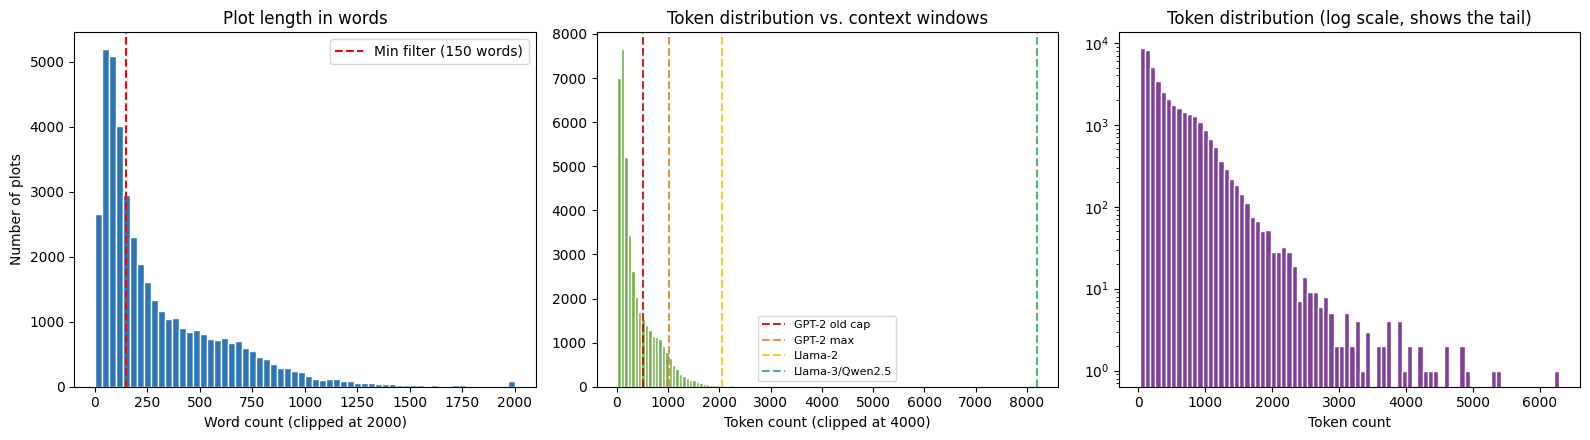

In [ ]:
# Plot length distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(df['word_count'].clip(upper=2000), bins=60, color='#2E75B6', edgecolor='white')
axes[0].axvline(150, color='red', linestyle='--', label='Min filter (150 words)', linewidth=1.5)
axes[0].set_xlabel('Word count (clipped at 2000)')
axes[0].set_ylabel('Number of plots')
axes[0].set_title('Plot length in words')
axes[0].legend()

axes[1].hist(df['token_count'].clip(upper=4000), bins=60, color='#70AD47', edgecolor='white')
for cap, label, color in [
    (512,  'GPT-2 old cap',   '#C00000'),
    (1024, 'GPT-2 max',        '#E67E22'),
    (2048, 'Llama-2',          '#F1C40F'),
    (8192, 'Llama-3/Qwen2.5', '#27AE60'),
]:
    axes[1].axvline(cap, color=color, linestyle='--', label=label, alpha=0.85, linewidth=1.5)
axes[1].set_xlabel('Token count (clipped at 4000)')
axes[1].set_title('Token distribution vs. context windows')
axes[1].legend(fontsize=8)

axes[2].hist(df['token_count'].dropna(), bins=80, color='#7F3F98', edgecolor='white')
axes[2].set_yscale('log')
axes[2].set_xlabel('Token count')
axes[2].set_title('Token distribution (log scale, shows the tail)')

plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/plot_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Temporal Coverage

This is the key audit for whether year-over-year analysis is feasible. We need dense genre × decade cells. Thin cells (fewer than ~30 films) produce unreliable stockiness estimates.

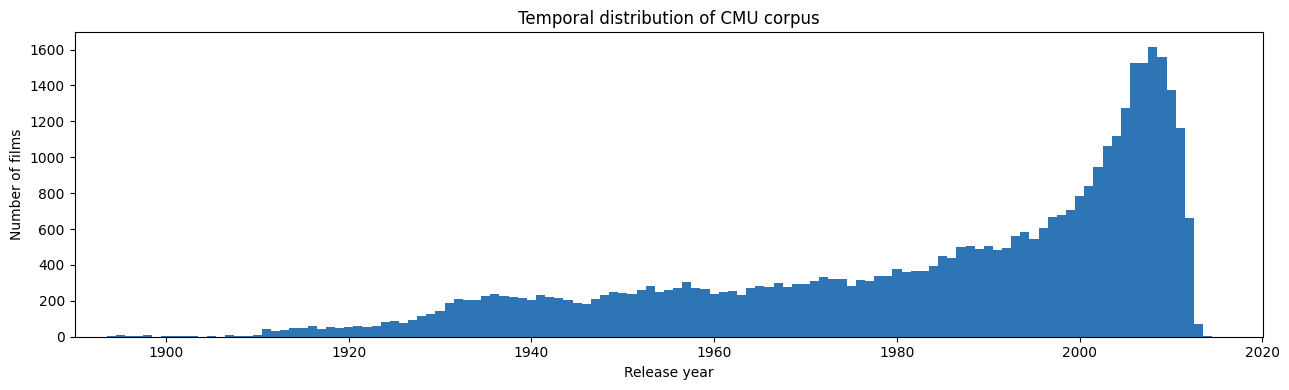


Films per decade:
  1890s:     30  
  1900s:     39  
  1910s:    428  █
  1920s:    812  ███
  1930s:  2,079  ████████
  1940s:  2,133  ████████
  1950s:  2,642  ██████████
  1960s:  2,666  ██████████
  1970s:  3,174  ████████████
  1980s:  4,237  █████████████████
  1990s:  5,827  ███████████████████████
  2000s: 12,246  ██████████████████████████████████████████████████
  2010s:  3,272  █████████████


In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(13, 4))
year_counts = df.dropna(subset=['year']).groupby(df['year'].dropna().astype(int)).size()
ax.bar(year_counts.index, year_counts.values, color='#2E75B6', edgecolor='none', width=1)
ax.set_xlabel('Release year')
ax.set_ylabel('Number of films')
ax.set_title(f'Temporal distribution of CMU corpus')
ax.set_xlim(1890, 2020)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/year_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nFilms per decade:')
decade_counts = df.dropna(subset=['decade']).groupby('decade').size()
max_count = decade_counts.max()
for decade, count in decade_counts.items():
    bar = '█' * int(count / max_count * 50)
    print(f'  {int(decade)}s: {count:>6,}  {bar}')

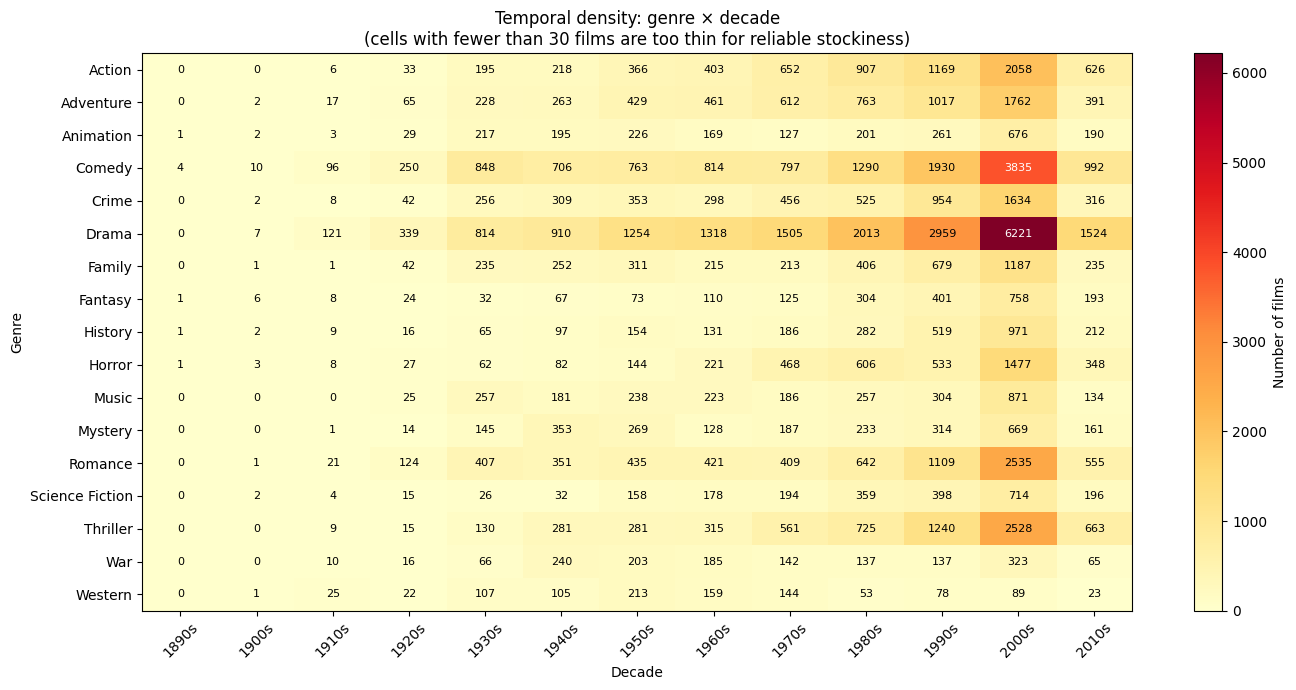

In [ ]:
# Genre × decade heatmap: the critical output for temporal feasibility
exploded = (df[df['n_canonical_genres'] > 0]
            .dropna(subset=['decade'])
            .explode('genres_canonical'))

heatmap_data = exploded.pivot_table(
    index='genres_canonical',
    columns='decade',
    values='wiki_id',
    aggfunc='count',
    fill_value=0
)

# Reorder rows to canonical order, drop any missing
heatmap_data = heatmap_data.reindex([g for g in CANONICAL_GENRES if g in heatmap_data.index])

fig, ax = plt.subplots(figsize=(14, 7))
im = ax.imshow(heatmap_data.values, aspect='auto', cmap='YlOrRd')

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels([f'{int(d)}s' for d in heatmap_data.columns], rotation=45)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

vmax = heatmap_data.values.max()
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.values[i, j]
        color = 'white' if value > vmax * 0.5 else 'black'
        ax.text(j, i, f'{int(value)}', ha='center', va='center', color=color, fontsize=8)

plt.colorbar(im, ax=ax, label='Number of films')
ax.set_title('Temporal density: genre × decade\n(cells with fewer than 30 films are too thin for reliable stockiness)')
ax.set_xlabel('Decade')
ax.set_ylabel('Genre')
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/genre_decade_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Identify thin cells that can't support reliable temporal stockiness
THRESHOLD = 30
thin_cells = (heatmap_data > 0) & (heatmap_data < THRESHOLD)

print(f'Cells with 1–{THRESHOLD-1} films (too thin for reliable per-decade stockiness):')
print(f'  {thin_cells.sum().sum()} of {(heatmap_data > 0).sum().sum()} non-empty cells\n')

print(f'Genres with thin coverage in any decade:')
for g in heatmap_data.index:
    thin_decades = [f'{int(d)}s' for d in heatmap_data.columns if thin_cells.loc[g, d]]
    if thin_decades:
        print(f'  {g:<18} thin in: {", ".join(thin_decades)}')

print(f'\nRecommendation: for thin genres, use 20-year or 30-year binning instead of decade.')

Cells with 1–29 films (too thin for reliable per-decade stockiness):
  43 of 203 non-empty cells

Genres with thin coverage in any decade:
  Action             thin in: 1910s
  Adventure          thin in: 1900s, 1910s
  Animation          thin in: 1890s, 1900s, 1910s, 1920s
  Comedy             thin in: 1890s, 1900s
  Crime              thin in: 1900s, 1910s
  Drama              thin in: 1900s
  Family             thin in: 1900s, 1910s
  Fantasy            thin in: 1890s, 1900s, 1910s, 1920s
  History            thin in: 1890s, 1900s, 1910s, 1920s
  Horror             thin in: 1890s, 1900s, 1910s, 1920s
  Music              thin in: 1920s
  Mystery            thin in: 1910s, 1920s
  Romance            thin in: 1900s, 1910s
  Science Fiction    thin in: 1900s, 1910s, 1920s, 1930s
  Thriller           thin in: 1910s, 1920s
  War                thin in: 1910s, 1920s
  Western            thin in: 1900s, 1910s, 1920s, 2010s

Recommendation: for thin genres, use 20-year or 30-year binning in

## 9. Filtering Preview

See what survives at different filter thresholds before committing to a cleaned corpus.

In [ ]:
print('Effect of plot length filter alone:')
print(f'{"Min words":>12}  {"Films remaining":>18}  {"% retained":>12}')
print('-' * 48)
for min_words in [0, 50, 100, 150, 200, 300, 500]:
    remaining = (df['word_count'] >= min_words).sum()
    pct = remaining / len(df) * 100
    print(f'{min_words:>12}  {remaining:>18,}  {pct:>11.1f}%')

print('\nCombined filter (plot length AND canonical genre AND valid year):')
print(f'{"Min words":>12}  {"Films remaining":>18}  {"% retained":>12}')
print('-' * 48)
for min_words in [50, 100, 150, 200]:
    remaining = (
        (df['word_count'] >= min_words) &
        (df['n_canonical_genres'] > 0) &
        (df['year'].notna())
    ).sum()
    pct = remaining / len(df) * 100
    print(f'{min_words:>12}  {remaining:>18,}  {pct:>11.1f}%')

Effect of plot length filter alone:
   Min words     Films remaining    % retained
------------------------------------------------
           0              42,204        100.0%
          50              37,746         89.4%
         100              29,793         70.6%
         150              24,075         57.0%
         200              20,230         47.9%
         300              15,301         36.3%
         500               9,360         22.2%

Combined filter (plot length AND canonical genre AND valid year):
   Min words     Films remaining    % retained
------------------------------------------------
          50              33,450         79.3%
         100              26,850         63.6%
         150              22,006         52.1%
         200              18,664         44.2%


## 10. Quality Spot Check

Random sample of plots for manual inspection. Look for: stubs, cast-list contamination, translation artifacts, reception sections bleeding into plot text, template junk.

In [ ]:
print('Random sample of 10 plots (min 50 words, has canonical genre):\n')
sample = df[
    (df['word_count'] > 50) &
    (df['n_canonical_genres'] > 0)
].sample(10, random_state=42)

for _, row in sample.iterrows():
    year_str = f'{int(row["year"])}' if pd.notna(row['year']) else 'N/A'
    print(f'--- {row["name"]} ({year_str}) ---')
    print(f'    Genres: {row["genres_canonical"]}')
    print(f'    Length: {row["word_count"]} words, {row["token_count"]} tokens')
    plot_preview = row['plot'][:350].replace('\n', ' ')
    print(f'    Plot:   {plot_preview}...')
    print()

Random sample of 10 plots (min 50 words, has canonical genre):

--- Calendar Girl (1993) ---
    Genres: ['Comedy', 'Drama']
    Length: 441 words, 539 tokens
    Plot:   Three young men  go on a trip to find Marilyn Monroe. While Marilyn Monroe is enjoying her rise to stardom and iconic pop culture status, three childhood friends are happy enough to sneakily obtain racy pictures of her for their pubescent enjoyment. Once they mature , Roy has his eyes set on joining the Military despite his strained relationship wi...

--- Sathi (2002) ---
    Genres: ['Drama', 'Music', 'Romance']
    Length: 520 words, 655 tokens
    Plot:   The film is a remake of Tamil film Thulladha Manamum Thullum. As the title suggests ' love is blind ' so is the context of the bioscope. The movie visualises the sacrifice made by the protagonist for his love. Bijoy ([[Jeet  is an aspiring singer with lots of talent, who resides in a village of Burdwan district. He has a caring and loving mother an...

--- Morgan

In [ ]:
# Also sample extreme tails: very short and very long plots
print('5 SHORTEST plots with canonical genres (likely stubs):\n')
shortest = df[df['n_canonical_genres'] > 0].nsmallest(5, 'word_count')
for _, row in shortest.iterrows():
    year_str = f'{int(row["year"])}' if pd.notna(row['year']) else 'N/A'
    print(f'  {row["name"]} ({year_str}, {row["word_count"]} words): {row["plot"][:200]}')

print('\n5 LONGEST plots with canonical genres (possible reception contamination):\n')
longest = df[df['n_canonical_genres'] > 0].nlargest(5, 'word_count')
for _, row in longest.iterrows():
    year_str = f'{int(row["year"])}' if pd.notna(row['year']) else 'N/A'
    print(f'  {row["name"]} ({year_str}, {row["word_count"]} words, {row["token_count"]} tokens)')

5 SHORTEST plots with canonical genres (likely stubs):

  Wild Seed (1965, 6 words): Dotson>{{cite web|lastHorace|title}{ http://voices.yahoo.com/wild-seed1965-review-8662797.html?cat27 April 2012|dateCastReferences {{Reflist}}
  The Church Mouse (1934, 9 words): A bank manager's prim and uptight Secretary suddenly blossoms.http://ftvdb.bfi.org.uk/sift/title/29419
  Manasina Maathu (N/A, 9 words): The film is about the family entertaining romantic story.http://www.cinefundas.com/2010/09/18/manasina-mathu-song-shooting
  Kote (2011, 10 words): The movie is based on a triangular love story. http://entertainment.oneindia.in/kannada/top-stories/2010/kote-shooting-halted-edga-011010.html
  Mate Bohu Kari Nei Jaa (2011, 10 words): The film is based on two families live in Bangkok.http://cinemasagar.com/2011/03/mate-bohu-kari-nei-ja-releasing-on-1st-april/

5 LONGEST plots with canonical genres (possible reception contamination):

  Wishology (N/A, 4929 words, 6286 tokens)
  Franklin and the 

## 11. Save Cleaned Corpus

Apply minimal filters: must have plot text, at least one canonical genre, at least 50 words. This is a loose filter. Notebook 02 can apply stricter thresholds if needed.

Output is Parquet for fast loading in downstream notebooks.

In [ ]:
cleaned = df[
    (df['word_count'] >= 50) &
    (df['n_canonical_genres'] > 0) &
    (df['plot'].notna()) &
    (df['plot'].str.len() > 0)
].copy()

keep_cols = [
    'wiki_id', 'name', 'year', 'decade',
    'plot', 'char_count', 'word_count', 'token_count',
    'genres_parsed', 'genres_canonical', 'n_canonical_genres',
    'languages', 'countries'
]
cleaned = cleaned[keep_cols].reset_index(drop=True)

output_path = f'{OUTPUT_DIR}/cmu_audited.parquet'
cleaned.to_parquet(output_path, engine='pyarrow', compression='snappy')

print(f'Saved cleaned corpus:')
print(f'  Path:  {output_path}')
print(f'  Rows:  {len(cleaned):,}  (from {raw_rows:,} raw, {len(cleaned)/raw_rows*100:.1f}% retained)')
print(f'  Size:  {os.path.getsize(output_path) / 1e6:.1f} MB')
print(f'  Columns: {list(cleaned.columns)}')

Saved cleaned corpus:
  Path:  /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01_audit/cmu_audited.parquet
  Rows:  35,249  (from 42,204 raw, 83.5% retained)
  Size:  45.8 MB
  Columns: ['wiki_id', 'name', 'year', 'decade', 'plot', 'char_count', 'word_count', 'token_count', 'genres_parsed', 'genres_canonical', 'n_canonical_genres', 'languages', 'countries']


In [ ]:
# Write a plain-text audit report alongside the parquet
report_path = f'{OUTPUT_DIR}/audit_report.txt'
with open(report_path, 'w') as f:
    f.write('CMU CORPUS AUDIT REPORT\n')
    f.write('=' * 60 + '\n\n')
    f.write(f'Raw rows (after plot+metadata join): {raw_rows:,}\n')
    f.write(f'Rows with valid year: {df["year"].notna().sum():,}\n')
    f.write(f'Rows with canonical genre: {(df["n_canonical_genres"] > 0).sum():,}\n')
    f.write(f'Rows in cleaned output: {len(cleaned):,}\n\n')
    f.write('TOKEN COUNT PERCENTILES\n')
    for p in [50, 75, 90, 95, 99, 99.9]:
        v = np.percentile(df['token_count'].dropna(), p)
        f.write(f'  p{p}: {v:.0f} tokens\n')
    f.write('\nCANONICAL GENRE COUNTS\n')
    for genre in CANONICAL_GENRES:
        f.write(f'  {genre:<18} {canon_counter[genre]:>6,}\n')

print(f'Wrote audit report: {report_path}')

Wrote audit report: /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/v4_rebuild/01_audit/audit_report.txt


## 12. Decisions for Notebook 02

Before building Notebook 02 (element extraction), answer these questions based on what this audit showed:

**Q1: Surprisal model context window.** Look at the truncation table. If fewer than 1% of plots exceed 8192 tokens, Llama-3.1-8B or Qwen2.5-7B handles the corpus with no truncation. If the tail is fatter, we need Qwen2.5's extended 32k context. If the p99 is under 4096, we have more options.

**Q2: Temporal binning strategy.** Look at the genre × decade heatmap. Which genres are thin in which decades? If Western is thin before 1920 and after 1990, we bin it as pre-1950 / 1950–1970 / 1970+ rather than by decade. Drama, Comedy, and Action are probably fine at decade resolution. Write down the per-genre binning scheme here.

**Q3: Quality threshold.** Did the short-plot and long-plot samples reveal problems? If short plots are mostly stubs with no real narrative, raise `MIN_WORDS` to 100 or 150. If long plots show reception contamination ("The film received mixed reviews…"), we need a cleaning regex pass before element extraction.

**Q4: Second corpus.** Is CMU's coverage (especially post-2010) strong enough to be our primary, or do we need Notebook 01b to pull Wikipedia Movie Plots from Kaggle as a replication corpus? Look at the temporal tail. If CMU dies out after 2012, that matters for the "conventions evolve" argument.

**Q5: Genre canonicalization coverage.** Look at the count of films that got zero canonical genres. If that number is large (>10%), our keyword mapping is too narrow and we're losing real movies to classification failure. Fix the mapping before proceeding.

Once these are answered, Notebook 02 builds the element extraction pipeline on `cmu_audited.parquet`.